# Describing a Table

A companion to the handout of the same name. Every cell runs on its own; the register is built by
the setup cell below, so nothing has to be downloaded first.

The register holds 9000 customer records with seven columns. Four are numeric (`age`, `income`,
`tenure_months`, `score`) and three are categorical (`region`, `plan`, `channel`). Three of the
numeric columns have missing values. The data is synthetic and seeded, so every number below is
reproducible.

In [36]:
#@title Setup: write register.csv  { display-mode: "form" }
# Nothing to read here. Run it, then carry on.
import base64, csv, gzip, io, os
import numpy as np
import matplotlib.pyplot as plt

_BLOB = (
    "..."
)

if not os.path.exists("register.csv"):
    with open("register.csv", "wb") as f:
        f.write(gzip.decompress(base64.b64decode(_BLOB)))

print("register.csv:", os.path.getsize("register.csv") // 1024, "KB")

register.csv: 364 KB


## 01 Reading a delimited file

Every field in a CSV file is text. Nothing in the file records what type a column is or what encoding it was written in, and the rules for splitting a line into fields are a convention rather than a standard.

In [37]:
# The first three lines, exactly as they sit on disk.
# newline="" switches off newline translation, so the line endings show as they are.
with open("register.csv", newline="", encoding="utf-8") as f:
    for _ in range(3):
        print(repr(f.readline()))

# The same first line read without it: \r\n has become \n before you ever see it.
print()
print(repr(open("register.csv", encoding="utf-8").readline()))

'age,income,tenure_months,score,region,plan,channel\r\n'
'47,,20,33.8,Southgate,legacy,shop\r\n'
'57,18581.51,19,45.8,Midland,basic,online\r\n'

'age,income,tenure_months,score,region,plan,channel\n'


The `,,` on the second record is a missing value, and it is an empty string. The lines end with
`\r\n`, which is what `csv.writer` writes by default.

In [38]:
with open("register.csv", newline="", encoding="utf-8") as f:
    records = list(csv.DictReader(f))

print(len(records), "rows")
print("columns:", list(records[0]))
print("first row:", records[0])

9000 rows
columns: ['age', 'income', 'tenure_months', 'score', 'region', 'plan', 'channel']
first row: {'age': '47', 'income': '', 'tenure_months': '20', 'score': '33.8', 'region': 'Southgate', 'plan': 'legacy', 'channel': 'shop'}


The csv module does its own line-ending handling, so its documentation asks for `newline=""` on any
file passed to it. On a file like this one the parsed rows are identical either way; the difference
shows in a quoted field that contains a newline of its own, and on writing, where the translation
can add a stray `\r`.

### What the format promises

There is no CSV standard that every writer follows. RFC 4180 describes the common form, and most
tools approximate it:

- Fields are separated by a delimiter. Usually a comma, but a semicolon where the comma is the
  decimal separator, and a tab in a file called TSV.
- A field containing the delimiter, a quotation mark or a newline is wrapped in quotation marks.
- A quotation mark inside a quoted field is written twice.
- The first line is a header by convention. Nothing in the file marks it as one.

None of that is enforced. The quoting rule is the one that decides how the file has to be read:
splitting on the delimiter tears any field that contains it.

In [4]:
import io

line = 'Smith, John,42,"Oxford, Oxfordshire"'

print("split ", line.split(","), "->", len(line.split(",")), "fields")
print("csv   ", next(csv.reader([line])), "->", len(next(csv.reader([line]))), "fields")

split  ['Smith', ' John', '42', '"Oxford', ' Oxfordshire"'] -> 5 fields
csv    ['Smith', ' John', '42', 'Oxford, Oxfordshire'] -> 4 fields


The other two rules have the same consequence. A doubled quotation mark is one character, not two, and a
newline inside a quoted field does not end the record.

In [5]:
doubled = 'id,note\n7,"she said ""no"" twice"\n'
print(list(csv.reader(io.StringIO(doubled)))[1])

wrapped = 'id,note\n7,"line one\nline two"\n'
print(len(list(csv.reader(io.StringIO(wrapped)))), "records, but",
      len(wrapped.strip().split("\n")), "lines")

['7', 'she said "no" twice']
2 records, but 3 lines


The csv module implements all three rules, which is why a CSV is read through it rather than through `str.split`.

### What the file does not say

Three things have to come from outside the file, and getting any of them wrong is silent.

- **The types.** Every field is text. That `47` is an age and `33.8` a score is a decision made by
  the reader.
- **The encoding.** Nothing in a CSV records whether it is UTF-8 or something older, so a name with
  an accent either survives or turns into mojibake depending on what the reader assumed.
- **What counts as missing.** An empty field is one convention. `NA`, `NULL`, `-999` and `-1` are
  others, and a reader that does not know about them will load a sentinel as a number and average
  it.

In [6]:
region = np.array([r["region"] for r in records])
tenure = np.array([float(r["tenure_months"]) for r in records])

print("region:", region.dtype, region.shape, region[:3])
print("tenure:", tenure.dtype, tenure.shape, tenure[:3])

region: <U9 (9000,) ['Southgate' 'Midland' 'Southgate']
tenure: float64 (9000,) [20. 19. 43.]


In [7]:
# The same conversion on a column that has gaps does not work.
try:
    income_broken = np.array([float(r["income"]) for r in records])
except ValueError as e:
    print("ValueError:", e)

ValueError: could not convert string to float: ''


### Mixed column types

`np.loadtxt` and `np.genfromtxt` read a delimited file straight into an array, and they fit a file
that is numeric throughout. This one is not: one array holds one dtype, so a table with text and
numbers in it has to become either several arrays or one array of strings, and an array of strings
cannot be averaged.

In [8]:
# this is the whole table as text, which is rarely what you want
as_text = np.genfromtxt("register.csv", delimiter=",", dtype=str, skip_header=1)
print(as_text.shape, as_text.dtype)
print(as_text[0])

(9000, 7) <U9
['47' '' '20' '33.8' 'Southgate' 'legacy' 'shop']


### One array per column

One array holds one dtype, so each column becomes its own array.

### One array for the whole table

One array per column is not the only option. The other is to make the text columns numeric and keep
the whole table in a single array: each category becomes an integer code, and the result is one
two-dimensional block of floats, one row per customer and one column per variable.

In [9]:
NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORICAL = ["region", "plan", "channel"]
CATEGORIES = {"region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
              "plan": ["basic", "standard", "premium", "legacy"],
              "channel": ["shop", "phone", "online"]}
COLUMNS = NUMERIC + CATEGORICAL
CODES = {c: {name: i for i, name in enumerate(CATEGORIES[c])} for c in CATEGORICAL}

rows = []
for r in records:
    numeric = [float(r[c]) if r[c] != "" else np.nan for c in NUMERIC]
    coded = [float(CODES[c][r[c]]) for c in CATEGORICAL]
    rows.append(numeric + coded)

table = np.array(rows, dtype=np.float32)
print("shape    ", table.shape)
print("first row", table[0])

shape     (9000, 7)
first row [47.   nan 20.  33.8  4.   3.   0. ]


Every per-column statistic now takes one call with `axis=0`, and the table is already the shape a
model is fed. The cost is that the codes are labels, not quantities: Southgate is 4 and Midland is
2, which does not make Southgate twice Midland.

In [10]:
print("codes for region:", CODES["region"])
print('the "mean region", which is nothing:', np.nanmean(table, axis=0)[4:])

codes for region: {'North': 0, 'Harbour': 1, 'Midland': 2, 'Eastfield': 3, 'Southgate': 4, 'Upland': 5}
the "mean region", which is nothing: [2.1211112 1.1572223 1.1457778]


Anything that reads the column as a quantity invents an order the categories do not have. The
repair is one column per category instead of one code, which is one-hot encoding.

### Pandas

The library `pandas` does all of the above in one call: `pd.read_csv("register.csv")` infers a type
per column, keeps the names, and represents empty fields as missing automatically. It is the
standard tool for this job and worth knowing by name. The point of doing it by hand once is that
the decisions it makes for you are exactly the ones that change the answers below.

## 02 Missing values and NaN

An empty field is not a zero and not an empty string once it reaches a numeric column. It needs a
value that arithmetic propagates rather than ignores: `np.nan`.

In [11]:
def column(name):
    """One numeric column as floats, with empty fields as NaN."""
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in records])

income = column("income")
print("dtype:", income.dtype)
print("first value:", income[0])

dtype: float64
first value: nan


### NaN propagates

In [12]:
# NaN propagates: one missing value is enough to poison a whole reduction.
print("income.sum() :", income.sum())
print("income.mean():", income.mean())
print("income.max() :", income.max())

income.sum() : nan
income.mean(): nan
income.max() : nan


### NaN is not equal to itself

In [13]:
# NaN is not equal to itself, so == never finds it.
print("np.nan == np.nan      :", np.nan == np.nan)
print("(income == np.nan).any():", (income == np.nan).any())
print()
print("np.isnan(income).sum()   :", np.isnan(income).sum(), "missing")
print("(~np.isnan(income)).sum():", (~np.isnan(income)).sum(), "present")

np.nan == np.nan      : False
(income == np.nan).any(): False

np.isnan(income).sum()   : 823 missing
(~np.isnan(income)).sum(): 8177 present


### Zero is not missing

Two shortcuts are common and both change the data. Writing `0.0` for a missing income adds 823
customers who earn nothing, which pulls the mean down and invents a spike at zero in every
histogram. Dropping every row that has any gap anywhere is the subject of section 05.

In [14]:
inc = column("income")
present = inc[~np.isnan(inc)]
as_zero = np.where(np.isnan(inc), 0.0, inc)

print(f"mean of the present values : {present.mean():>9.2f}")
print(f"mean with gaps set to zero : {as_zero.mean():>9.2f}")

mean of the present values :  32102.02
mean with gaps set to zero :  29166.47


## 03 Counting rows and categories

Before any statistic, two counts: how many rows there are, and how they are spread across the categories
of each categorical column.

In [15]:
plan = np.array([r["plan"] for r in records])

print('(plan == "premium").sum():', (plan == "premium").sum())
print("np.unique(plan)          :", np.unique(plan))

names, counts = np.unique(plan, return_counts=True)
for name, n in zip(names, counts):
    print(f"   {name:<10} {n}")

(plan == "premium").sum(): 1915
np.unique(plan)          : ['basic' 'legacy' 'premium' 'standard']
   basic      3048
   legacy     1274
   premium    1915
   standard   2763


### Categories with no rows

`np.unique` returns the categories in alphabetical order and reports only the categories that
occur. If a category is defined by the domain and happens to be absent, it is missing from the output. Counting
against a fixed list avoids that and makes the zero visible.

In [16]:
col = np.array([r["plan"] for r in records])
counts = {name: int((col == name).sum()) for name in CATEGORIES["plan"]}
print(counts)
print("sum:", sum(counts.values()), "of", len(records), "rows")

{'basic': 3048, 'standard': 2763, 'premium': 1915, 'legacy': 1274}
sum: 9000 of 9000 rows


Checking that the counts add up to the number of rows catches a misspelled category, a trailing space
in the file, and a category that was not in the list.

**Try it.** Change `"plan"` above to `"region"` or `"channel"` and run it again.

### Missing values per column

The same counting question applied to the gaps.

**Try it.** Count the missing values in each of the four numeric columns.

In [17]:
for name in ["age", "income", "tenure_months", "score"]:
    v = column(name)
    print(f"{name:<14} missing {int(np.isnan(v).sum()):>4}   present {int((~np.isnan(v)).sum()):>5}")

age            missing  542   present  8458
income         missing  823   present  8177
tenure_months  missing    0   present  9000
score          missing  361   present  8639


One column has no gaps at all. That is as much a result as the others.

## 04 Summary statistics

Five numbers describe a numeric column: where it sits, how wide it is, and where it ends.

In [18]:
score = column("score")
s = score[~np.isnan(score)]          # drop the gaps once, reuse below

print("n       ", len(s))
print("mean    ", round(float(s.mean()), 2))
print("median  ", round(float(np.median(s)), 2))
print("std     ", round(float(s.std()), 2))
print("min, max", float(s.min()), float(s.max()))
print("quartiles", np.quantile(s, [0.25, 0.5, 0.75]))

n        8639
mean     58.73
median   58.8
std      13.2
min, max 9.7 100.0
quartiles [49.8 58.8 67.7]


### Every column at once

With the table in one array a reduction takes `axis=0` and returns one value per column. The axis
named is the one that disappears, so a `(9000, 7)` table reduces to `(7,)`.

In [19]:
print("plain mean  ", table.mean(axis=0))          # NaN poisons three of the four numeric columns
print("nanmean     ", np.nanmean(table, axis=0)[:4])
print("nanmin      ", np.nanmin(table, axis=0)[:4])
print("nanmax      ", np.nanmax(table, axis=0)[:4])
print("result shape", np.nanmean(table, axis=0).shape)

plain mean   [       nan        nan 26.410444         nan  2.1211112  1.1572223
  1.1457778]
nanmean      [4.3135021e+01 3.2102016e+04 2.6410444e+01 5.8725746e+01]
nanmin       [  18.   5600.49    0.      9.7 ]
nanmax       [8.4000000e+01 1.4802597e+05 1.7400000e+02 1.0000000e+02]
result shape (7,)


Pair the result with the column names to read it. `map(float, ...)` is there because NumPy
prints its own scalar types in full, as `np.float32(43.14)` rather than `43.14`.

In [20]:
for name, value in zip(COLUMNS, map(float, np.nanmean(table, axis=0))):
    print(f"   {name:<14} {value:>10.2f}")

   age                 43.14
   income           32102.02
   tenure_months       26.41
   score               58.73
   region               2.12
   plan                 1.16
   channel              1.15


Counting works the same way, and `axis` chooses what is being counted.

In [21]:
missing = np.isnan(table)

print("per column       ", np.count_nonzero(missing, axis=0))
print("rows with a gap  ", np.count_nonzero(np.any(missing, axis=1)))
print("columns with gaps", np.where(np.any(missing, axis=0))[0],
      [COLUMNS[i] for i in np.where(np.any(missing, axis=0))[0]])

per column        [542 823   0 361   0   0   0]
rows with a gap   1622
columns with gaps [0 1 3] ['age', 'income', 'score']


The middle line is the listwise count of section 05 in one expression: 1622 of 9000 rows have a
gap somewhere, which is why complete-case analysis keeps only 7378.

### Sorting, with gaps

`np.sort` returns a sorted copy and `np.argsort` returns the order rather than the values. On a
column with gaps both put NaN at the end, which makes the smallest values easy to reach and the
largest ones a trap.

In [22]:
inc = table[:, 1]                # income, 823 of the 9000 missing

print("three smallest", np.sort(inc)[:3])
print("three largest?", np.sort(inc)[-3:], "  <- not what was asked")

three smallest [5600.49 6104.75 6459.16]
three largest? [nan nan nan]   <- not what was asked


Two ways round it. Drop the gaps before sorting, or send them to the other end with
`-np.inf`, negative infinity, a float that compares below every real number.

In [23]:
present = inc[~np.isnan(inc)]
print("dropped then sorted", np.sort(present)[-3:])

filled = inc.copy()
filled[np.isnan(filled)] = -np.inf
print("-inf then sorted   ", np.sort(filled)[-3:])

dropped then sorted [143798.83 146627.45 148025.97]
-inf then sorted    [143798.83 146627.45 148025.97]


`np.argsort` answers "which rows", so one column can be ordered and another read off it. Dropping
the gaps breaks that, because every index after a dropped row shifts.

In [24]:
order = np.argsort(inc)
n_missing = int(np.isnan(inc).sum())
top3 = order[-n_missing - 3 : -n_missing]

print("naive     ", inc[order[-3:]])
print("corrected ", inc[top3])
print("their ages", table[top3, 0])

carried = np.flatnonzero(~np.isnan(inc))[np.argsort(present)][-3:]
print("same rows via carried indices:", np.array_equal(carried, top3))

naive      [nan nan nan]
corrected  [143798.83 146627.45 148025.97]
their ages [59. 83. 72.]
same rows via carried indices: True


`np.sort` also takes an axis, and on a table it sorts every column independently. Its rows are no
longer customers: the smallest age and the smallest income almost certainly belong to two different
people.

In [25]:
print(np.sort(table, axis=0)[:3])

[[  18.   5600.49    0.      9.7     0.      0.      0.  ]
 [  18.   6104.75    0.     12.4     0.      0.      0.  ]
 [  18.   6459.16    0.     14.2     0.      0.      0.  ]]


### Quantiles

`np.quantile(s, q)` returns the value below which the fraction `q` of the data falls. The
three at 0.25, 0.5 and 0.75 are the quartiles: a quarter of the scores sit below 49.8, half
below 58.8, three quarters below 67.7. The middle one is the median by definition. Where the
fraction does not land on an observation NumPy interpolates between the two either side, so a
quartile is usually not a value present in the data. `np.percentile` is the same thing on a 0
to 100 scale.

The gap between the outer two is the interquartile range, 17.9 here: the spread of the middle
half, computed without reference to the mean.


In [26]:
q = np.quantile(s, [0.25, 0.5, 0.75])
print("quartiles         ", q)
print("median matches q2 ", float(np.median(s)) == float(q[1]))
print("interquartile range", round(float(q[2] - q[0]), 1))
print("fraction below q1 ", round(float((s < q[0]).mean()), 3))


quartiles          [49.8 58.8 67.7]
median matches q2  True
interquartile range 17.9
fraction below q1  0.248


### Mean against median

On a symmetric column they nearly agree. On a skewed one they do not, and the gap describes the
shape.

In [27]:
inc = income[~np.isnan(income)]
print("income mean  ", round(float(inc.mean()), 2))
print("income median", round(float(np.median(inc)), 2))
print("difference   ", round(float(inc.mean() - np.median(inc)), 2))

income mean   32102.02
income median 28117.74
difference    3984.28


Mean above median is the signature of a long right tail.

### ddof

`np.std` divides by `n`. Many texts and `statistics.stdev` divide by `n - 1`. NumPy exposes the
choice as `ddof` and defaults it to 0.

The correction exists because the deviations are measured from the sample mean, which sits exactly
where it makes them as small as possible, so dividing by `n` understates the spread by a factor of
`(n - 1) / n` every time.

Which one to use follows from what the rows are. The question here is how spread out *these*
8639 scores are, a statement about the rows in hand, so `ddof=0` answers it exactly and NumPy's
default is right. `ddof=1` is for the other question: the rows are a sample, and the number is an
estimate of the spread of a larger population you cannot measure. The gap is the fourth digit
here, 2.6 per cent at twenty values and 12 per cent at five, so it is a decision that only shows
up on small data.

In [28]:
print("ddof=0 (divides by n)    ", round(float(s.std()), 4))
print("ddof=1 (divides by n - 1)", round(float(s.std(ddof=1)), 4))

small = s[:20]
print()
print("on 20 values: ddof=0", round(float(small.std()), 3),
      " ddof=1", round(float(small.std(ddof=1)), 3))

ddof=0 (divides by n)     13.2042
ddof=1 (divides by n - 1) 13.2049

on 20 values: ddof=0 15.304  ddof=1 15.702


### Robustness to one extreme value

One impossible value, a typing error of an extra digit, moves the five statistics by wildly
different amounts.

In [29]:
t = np.append(s, 10_000.0)           # one impossible score

print("mean   moves by", round(float(t.mean() - s.mean()), 2))
print("median moves by", round(float(np.median(t) - np.median(s)), 2))
print("max    moves by", round(float(t.max() - s.max()), 2))
print("std    moves by", round(float(t.std() - s.std()), 2))

mean   moves by 1.15
median moves by 0.0
max    moves by 9900.0
std    moves by 94.55


The median and the quartiles are robust: they depend on the order of the values, not their size. The
mean, the standard deviation and the extremes are not. An impossible value usually shows up in `min`
or `max`, so printing those first is the shortest check on a new column.

## 05 Pairwise and listwise deletion

Leaving a missing value out of a calculation can mean dropping the whole row or dropping only
that one value. The two give different numbers.

**Listwise deletion**, or complete-case analysis, drops every row with a gap in any column.
**Pairwise deletion**, or available-case analysis, keeps for each statistic every row where the
columns that statistic needs are present.

In [30]:
age, score_c = column("age"), column("score")
inc_c, ten_c = column("income"), column("tenure_months")

complete = ~np.isnan(age) & ~np.isnan(inc_c) & ~np.isnan(score_c) & ~np.isnan(ten_c)

print("rows total           ", len(records))
print("rows fully complete  ", int(complete.sum()))
print("lost to listwise     ", len(records) - int(complete.sum()),
      f"({(len(records) - int(complete.sum())) / len(records):.1%})")
print()
print("mean score, pairwise :", round(float(score_c[~np.isnan(score_c)].mean()), 4),
      f"over {int((~np.isnan(score_c)).sum())} rows")
print("mean score, listwise :", round(float(score_c[complete].mean()), 4),
      f"over {int(complete.sum())} rows")

rows total            9000
rows fully complete   7378
lost to listwise      1622 (18.0%)

mean score, pairwise : 58.7257 over 8639 rows
mean score, listwise : 58.7841 over 7378 rows


The first is the mean of every score that is present. The second is the mean score among
customers whose record is complete in all four columns, a different population and not the one
the question named.

### Functions that ignore NaNs

NumPy ships a parallel set of reductions that skip NaN instead of propagating it. They are exactly
pairwise deletion, written shorter.

In [31]:
print("np.nanmean  ", round(float(np.nanmean(score_c)), 4))
print("by hand     ", round(float(score_c[~np.isnan(score_c)].mean()), 4))
print("identical   ", np.nanmean(score_c) == score_c[~np.isnan(score_c)].mean())
print()
for f in (np.nansum, np.nanmean, np.nanmedian, np.nanstd, np.nanmin, np.nanmax):
    print(f"{f.__name__:<12}", round(float(f(score_c)), 3))

np.nanmean   58.7257
by hand      58.7257
identical    True

nansum       507331.5
nanmean      58.726
nanmedian    58.8
nanstd       13.204
nanmin       9.7
nanmax       100.0


## 06 Grouped summaries

The average score in each region. The average income on each plan. One number per category instead
of one number for the whole column.

Asking it of the whole column gives `58.73`, the mean score of every customer. Asking it region by
region gives six numbers, and they run from 51 to 67, which the single number hid completely.

Each of those six is an ordinary mean over a subset of the rows, and a boolean mask picks the
subset: `region == "Upland"` is True on the Upland rows, `~np.isnan(score_c)` is True on the rows
that have a score, and `&` keeps the rows where both hold.

In [32]:
region = np.array([r["region"] for r in records])

for name in CATEGORIES["region"]:
    sel = (region == name) & ~np.isnan(score_c)
    print(f"{name:<10} n={int(sel.sum()):>5}  mean score {float(score_c[sel].mean()):6.2f}")

North      n= 1924  mean score  50.99
Harbour    n= 1555  mean score  61.21
Midland    n= 1740  mean score  58.89
Eastfield  n= 1197  mean score  64.99
Southgate  n= 1369  mean score  55.65
Upland     n=  854  mean score  67.46


Print the group size next to every group statistic. A mean over 854 rows and a mean over 1924 rows
are not equally trustworthy, and a group that has quietly become empty gives a NaN that is otherwise
hard to explain.

**Try it.** Swap the numeric column for `income` and the categorical one for `plan`.

### Deletion inside a group

The mask above tests the column being averaged. Testing completeness across all columns instead
changes every group, and unevenly, because the gaps are not spread evenly across regions. The rule
is the same as section 05: skip on the column the statistic is about.

In [33]:
complete = (~np.isnan(column("age")) & ~np.isnan(column("income"))
            & ~np.isnan(score_c) & ~np.isnan(column("tenure_months")))

pairwise = (region == "Upland") & ~np.isnan(score_c)
listwise = (region == "Upland") & complete

print(f"pairwise {score_c[pairwise].mean():.2f} over {int(pairwise.sum())} rows")
print(f"listwise {score_c[listwise].mean():.2f} over {int(listwise.sum())} rows")

pairwise 67.46 over 854 rows
listwise 67.29 over 726 rows


## 07 Bar charts

Four counts in a column of text have to be compared by reading them. The same four as bars are
compared by looking. `plt.bar` draws them in three lines, and the rest of the work is labelling.

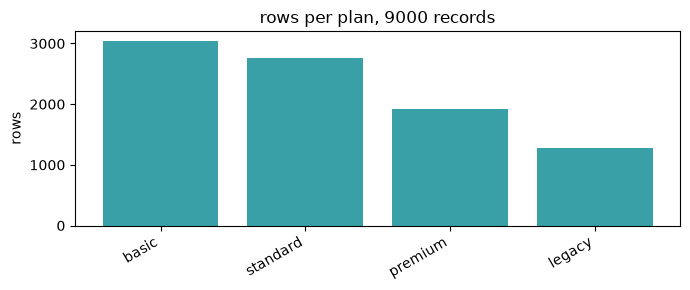

In [34]:
names = CATEGORIES["plan"]
values = [int((plan == name).sum()) for name in names]

plt.figure(figsize=(7, 3))
plt.bar(range(len(names)), values, color="#39a0a8")
plt.xticks(range(len(names)), names, rotation=30, ha="right")
plt.ylabel("rows")
plt.title(f"rows per plan, {len(records)} records")
plt.tight_layout()
plt.show()

`plt.bar` places bars at the x positions it is given, so the positions are `range(len(names))` and
the names are attached afterwards with `plt.xticks`. Rotating long labels and anchoring them at
their right end keeps them from overlapping. `plt.tight_layout()` resizes the axes so the rotated
labels sit inside the figure.

### Axis labels and counts

A chart needs a labelled y axis, every category including the empty ones, and the number of rows it
was drawn from.

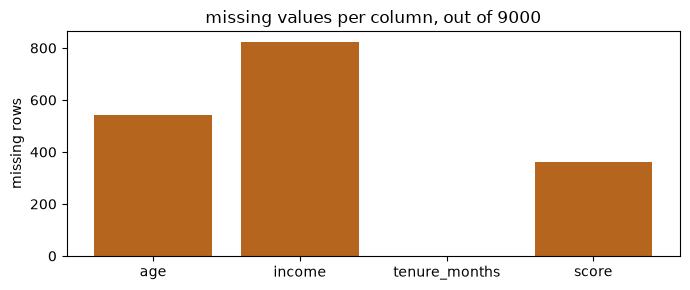

In [35]:
# Missing values per column, as a chart rather than a table.
cols = ["age", "income", "tenure_months", "score"]
miss = [int(np.isnan(column(c)).sum()) for c in cols]

plt.figure(figsize=(7, 3))
plt.bar(range(len(cols)), miss, color="#b5651d")
plt.xticks(range(len(cols)), cols)
plt.ylabel("missing rows")
plt.title(f"missing values per column, out of {len(records)}")
plt.tight_layout()
plt.show()

The column with no gaps gets a bar of height zero, which is visible because the category is in the list.

## 08 Loop forms and array equivalents

| what the loop does | as an array expression |
|---|---|
| Rows in one category | `(plan == "premium").sum()` |
| Rows in every category, in a chosen order | `[(plan == name).sum() for name in CATEGORIES]` |
| Distinct categories and their counts | `np.unique(plan, return_counts=True)` |
| How many values are missing | `np.isnan(v).sum()` |
| How many are present | `(~np.isnan(v)).sum()` |
| Mean, skipping the gaps | `np.nanmean(v)` |
| Median and spread, skipping the gaps | `np.nanmedian(v)`, `np.nanstd(v)` |
| Extremes, skipping the gaps | `np.nanmin(v)`, `np.nanmax(v)` |
| Quartiles | `np.quantile(v[~np.isnan(v)], [.25, .5, .75])` |
| Mean within one group | `v[(cat == name) & ~np.isnan(v)].mean()` |

### Further reading

- [The csv module](https://docs.python.org/3/library/csv.html), for `DictReader`, dialects and quoting.
- [Statistics routines](https://numpy.org/doc/stable/reference/routines.statistics.html), which lists
  the NaN-ignoring function beside each ordinary one.
- [isnan](https://numpy.org/doc/stable/reference/generated/numpy.isnan.html) and
  [unique](https://numpy.org/doc/stable/reference/generated/numpy.unique.html).
- [pyplot.bar](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.bar.html).
